# Interpreting Latent Gene Space

In [ ]:
import scanpy as sc
import ggml_ot

ggml_ot.settings.random_seed = 42
ggml_ot.settings.device = "cuda"  # set to "cpu" if cuda not available

In this tutorial, we explore the biological interpretation of the model learned with `ggml_ot`. We demonstrate functions to compute and visualize:
- low-dimensional cell embedding in the learned subspace
- gene rankings of latent components
- gene enrichment analysis of latent components

First, we load the example dataset from CELLxGENE (Myocardial Infarction from Kuppe et al., 2022) where patients are labelled by tissue state: **myogenic** (remote myocardium), **ischemic** (acute injury zone) and **fibrotic** (scar / remodeled zone).

Then we train the model to separate disease states as shown in the [Quickstart Tutorial](../tutorials/1_basic_tutorial.html). 

Compute all OT distances after 30 iterations


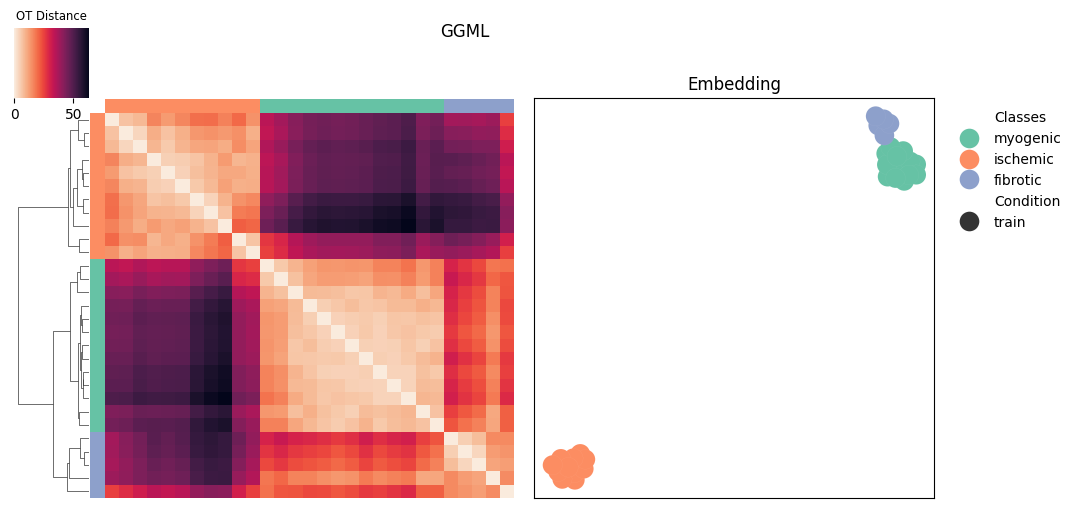

In [18]:
# Wrapper around load_cellxgene(...) + from_anndata(...) for this example dataset.
# See the dataset-loading tutorial for using your own AnnData object.
dataset = ggml_ot.data.myocardial_infarction(n_top_genes=2000, normalize=True)
adata = dataset.adata

n_comps = 2
dataset.train(n_comps=n_comps, entropic_reg=5.0, reg_type=1)

The clustermap and embeddig clearly show that the patient-level OT distances with the learned ground metric capture the annotated disease states. We will now demonstrate how to interpret the learned model to identify biomarkers and disease-related processes.

## Learned Latent Gene Space

Let's have a look at the cell-level distances of the learned ground metric, i.e. the cells in the learned latent gene space that captures the patient's disease state under OT. The axes (`X_ggml1`,`X_ggml2`) are the latent components which are linear combinations of genes. Intuitively, you can think of these as PCA loadings that capture the patients disease state instead of maximizing the overall variance.

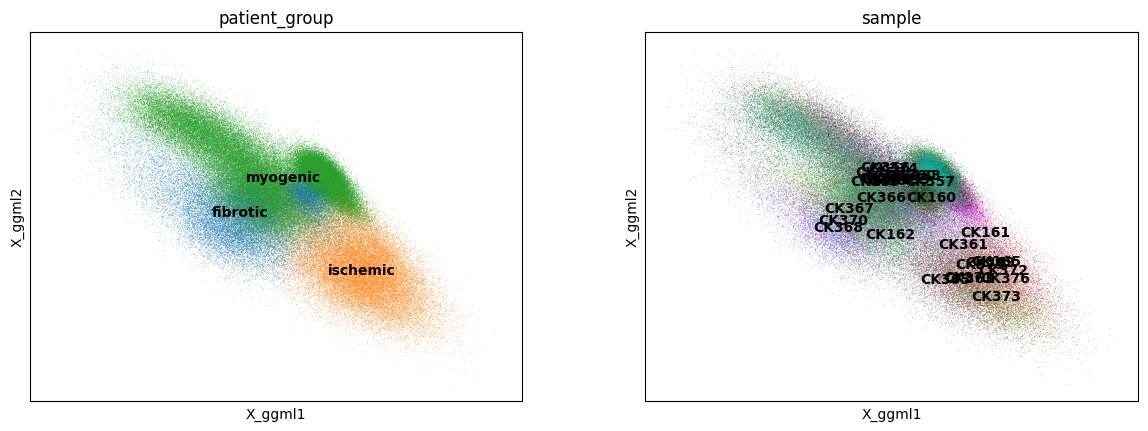

In [19]:
adata = dataset.adata

# Show cells embedded in low-dimensional gene subspace (adata.obsm["X_ggml"])
sc.pl.embedding(adata, basis="X_ggml", color=["patient_group", "sample"], legend_loc="on data")

Comparing this to a traditional UMAP of the full gene space, clearly shows the significantly improved separation of disease states.

*Note: If you AnnData has no `.obsm["X_umap"]` yet, compute it first with Scanpy: `sc.pp.neighbors(adata)`; `sc.tl.umap(adata)`.*

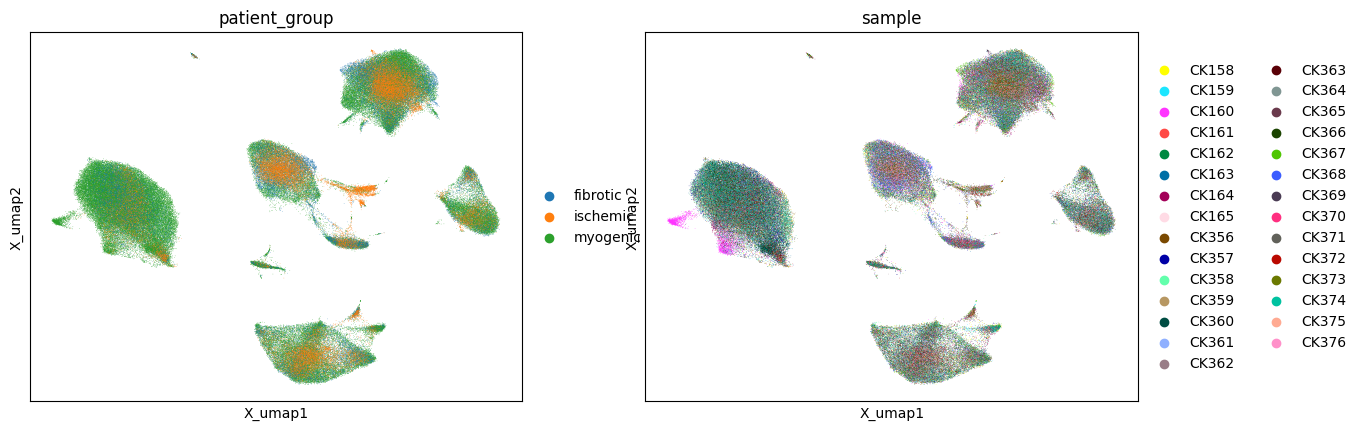

In [20]:
# Show cells embedded in low-dimensional gene subspace (adata.obsm["X_ggml"])
sc.pl.embedding(adata, basis="X_umap", color=["patient_group", "sample"])

## Gene Ranking of Latent Components

The function ``gene.ranking`` ranks the genes for each component of the learned latent gene space. It behaves like `scanpy.pl.pca_loadings`, but on `.varm["W_ggml"]` instead of `.varm["PCs]`.

Here, we plot the top 50 genes for each component. Both large positive and negative ranked values have a high importance in separating cells in the respective component.

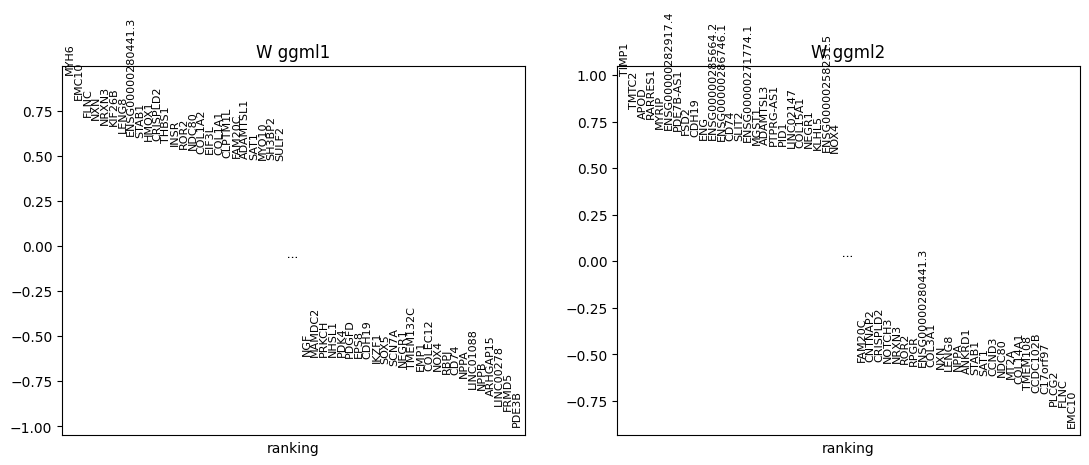

In [21]:
top_genes = ggml_ot.gene.ranking(adata, n_genes=50, gene_symbols="feature_name")

Component 1 contrasts cardiomyocyte-expressed genes (`MYH6`, `EMC10`) with remodeling/stress genes (`PDE3B`, `FRMD5`), separating remote (myogenic) from injured myocardium. Notably, `PDE3B` inhibition has been linked to reduced infarct size in ischemia–reperfusion models.

Component 2 separates fibrotic / ECM-remodeling markers (`TIMP1`, `TMTC2`, `APOD`, `RARRES1`) from the cardiomyocyte-produced `EMC10`, placing fibrotic tissue opposite preserved myocardium.

Below we show the expression of the top ranked genes for the latent cell embeddings. 

Top Ranked Genes in W_ggml 1: MYH6, EMC10, ..., FRMD5, PDE3B


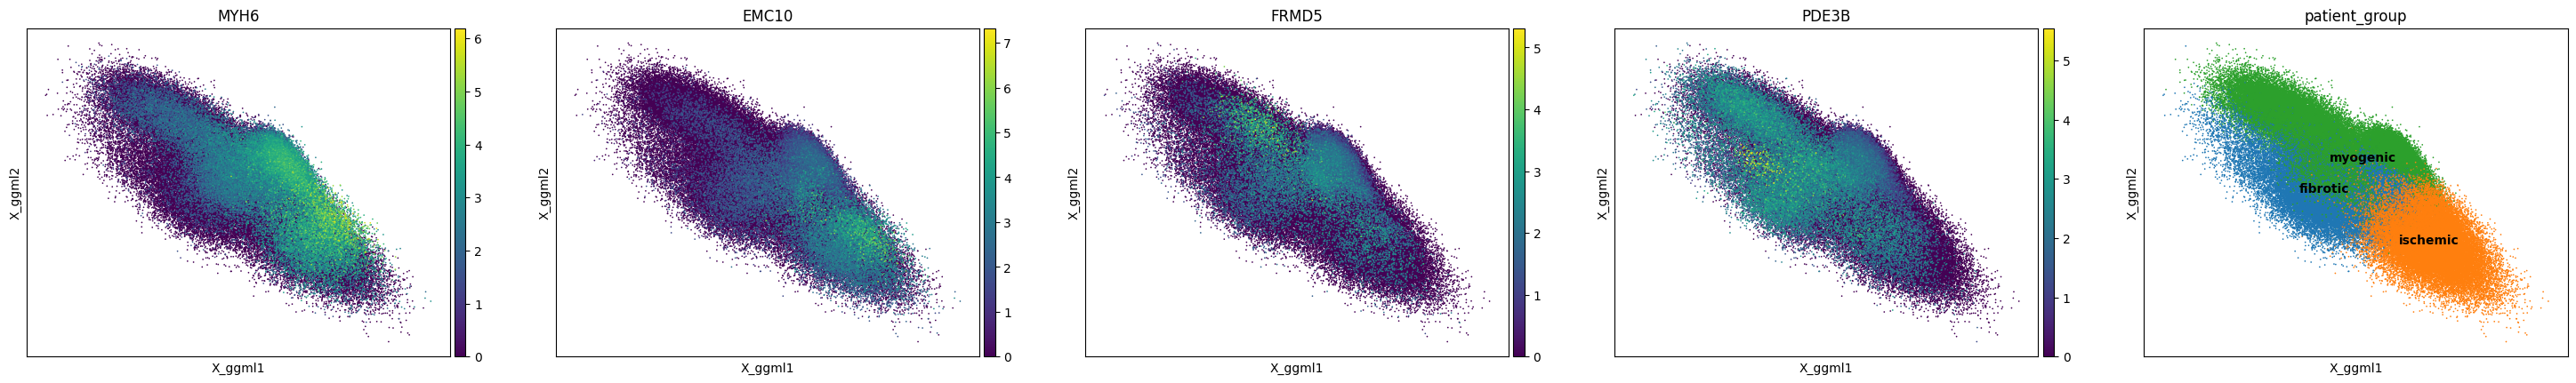

Top Ranked Genes in W_ggml 2: TIMP1, TMTC2, ..., FLNC, EMC10


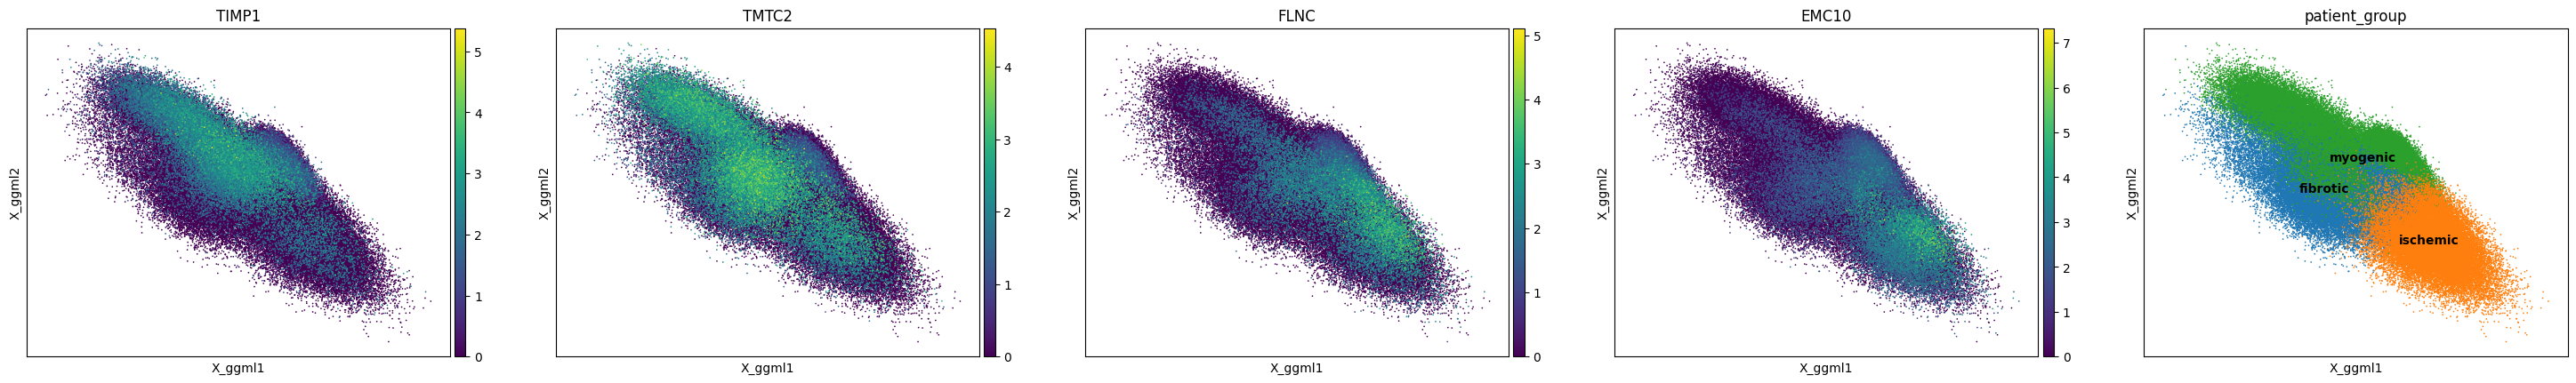

In [34]:
# Plot gene expression in latent space
for c in range(n_comps):
    print(
        f"Top Ranked Genes in W_ggml {c + 1}: {', '.join(top_genes[c, [0, 1]])}, ..., {', '.join(top_genes[c, [-2, -1]])}"
    )
    sc.pl.embedding(
        adata,
        basis="X_ggml",
        color=list(top_genes[c, [0, 1, -2, -1]]) + ["patient_group"],
        s=6,
        gene_symbols="feature_name",
        use_raw=False,
        legend_loc="on data",
        ncols=5,
    )

## Gene Enrichment of Latent Components

``gene.enrichment()`` runs over-representation analysis via g:Profiler on the top-ranked genes of each loading to identify associated biological processes and pathways.

In the following, we consider top 50 genes for each loading and perform gene enrichment analysis.

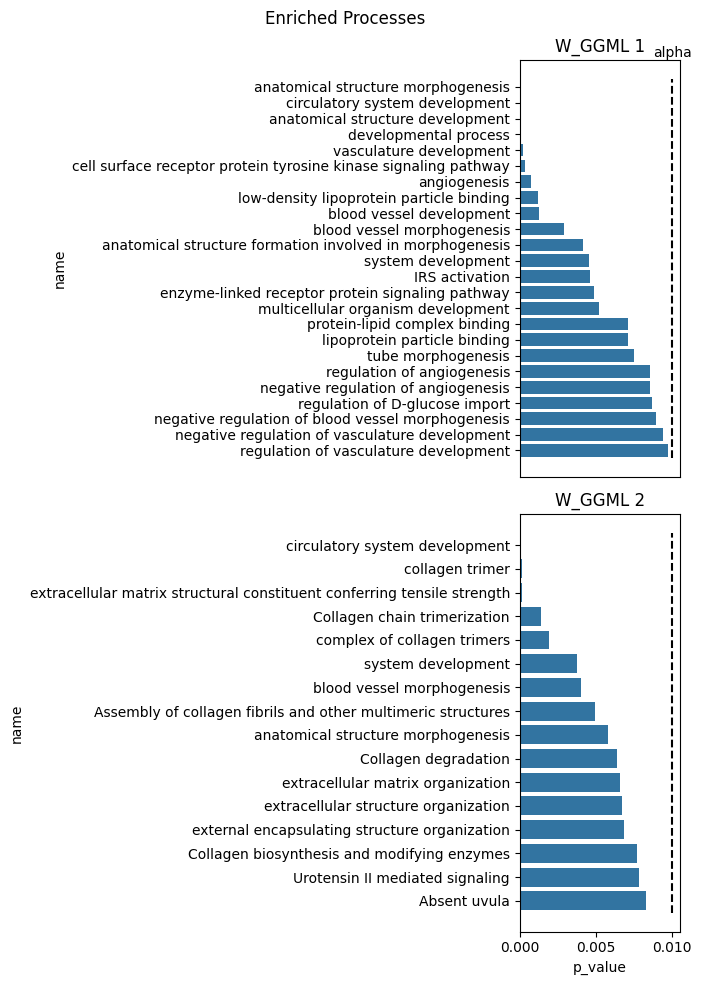

In [7]:
ggml_ot.gene.enrichment(adata, gene_symbols="feature_name", ordered=True, n_genes=50, alpha=0.01)

Component 1 enriches for heart development, response to wounding, and regulation of muscle cell proliferation, consistent with a contrast between remote and injured myocyte programs.
Component 2 is dominated by ECM organization, collagen fibril organization, and collagen biosynthesis terms alongside vasculature development, matching the fibrotic-niche signature reported in Kuppe et al. (2022) and the accompanying post-injury angiogenic response. 

*Note: loadings and enrichment are computed on the highly variable genes only, so processes driven by genes outside this set cannot appear. The enrichment is exploratory, p-values reflect hypergeometric overlap and are not cross-validated against held-out patients.*

## Higher Latent Dimensions

Learning a higher-dimensional latent space allows a more nuanced view of different processes separated into multiple axes. It also increases the risk of overfitting, see the [Hyperparameter Tuning Tutorial](../tutorials/3_hyperparameter_tuning.html) for automatically tuning `n_comps` and evaluating generalizability.

Below we re-load the data through the shortcut with a wider gene set. Since highly variable gene filtering subsets the AnnData in place, this keeps the first analysis unchanged while giving the gene-interpretation step 5000 HVGs.

Compute all OT distances after 18 iterations


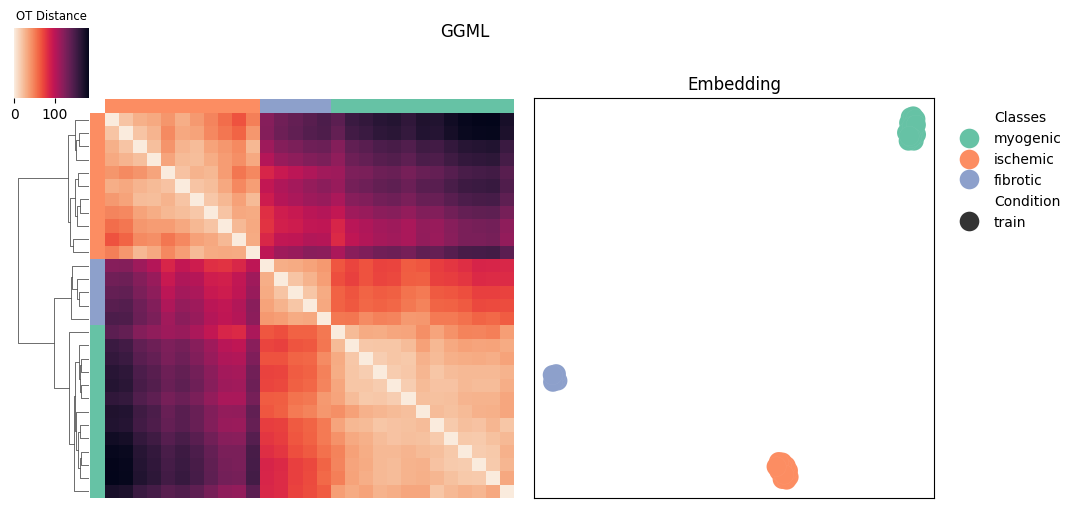

In [8]:
# Wrapper around load_cellxgene(...) + from_anndata(...) for this example dataset.
# See the dataset-loading tutorial for using your own AnnData object.
dataset = ggml_ot.data.myocardial_infarction(n_top_genes=5000, normalize=True)
adata = dataset.adata

n_comps = 5
dataset.train(n_comps=n_comps, entropic_reg=5.0, reg_type=1)

adata = dataset.adata

To visualize, we can either plot the different latent axis combinations directly, or compute a 2D UMAP of the latent space as shown in the more detailed tutorial.

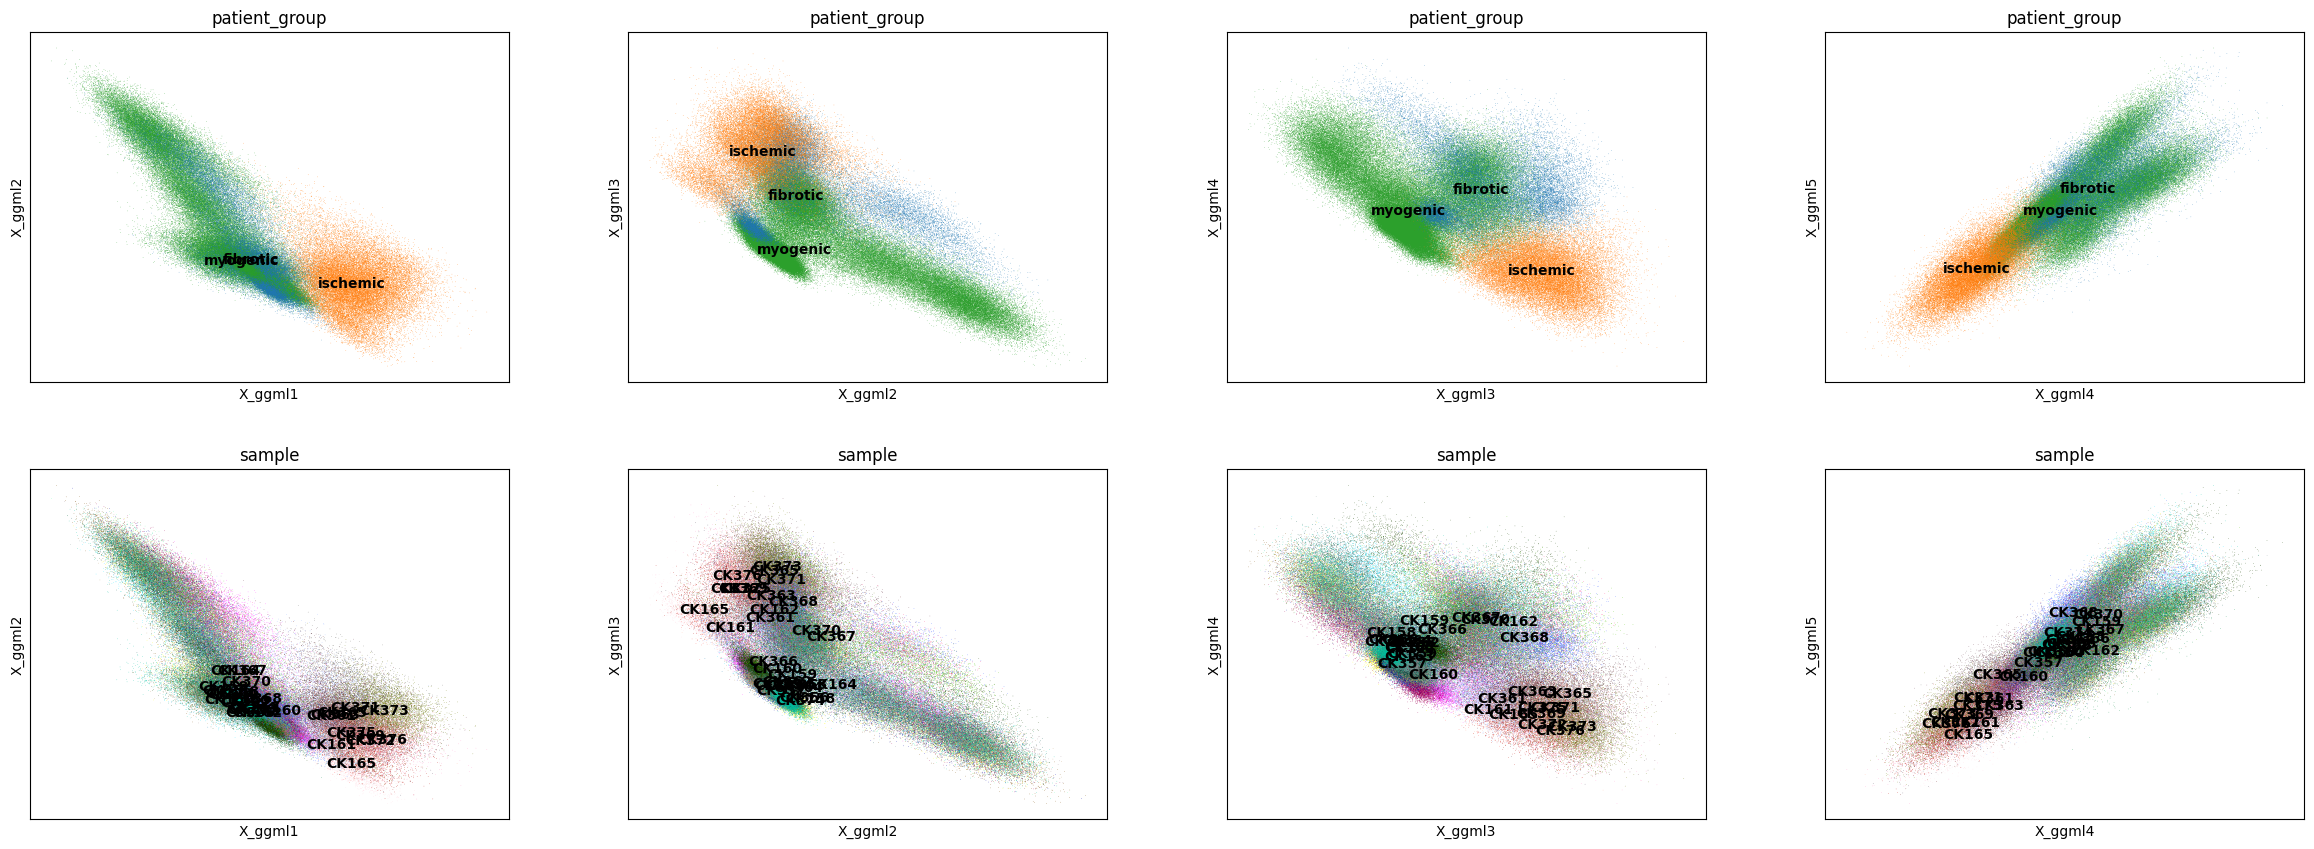

In [9]:
component_pairs = [f"{i},{i + 1}" for i in range(1, n_comps)]
sc.pl.embedding(
    adata, basis="X_ggml", color=["patient_group", "sample"], components=component_pairs, legend_loc="on data"
)

The enrichment below uses a stricter `alpha=0.001` because the larger HVG set and additional components yield many terms that pass `0.01`, which would clutter the plot.

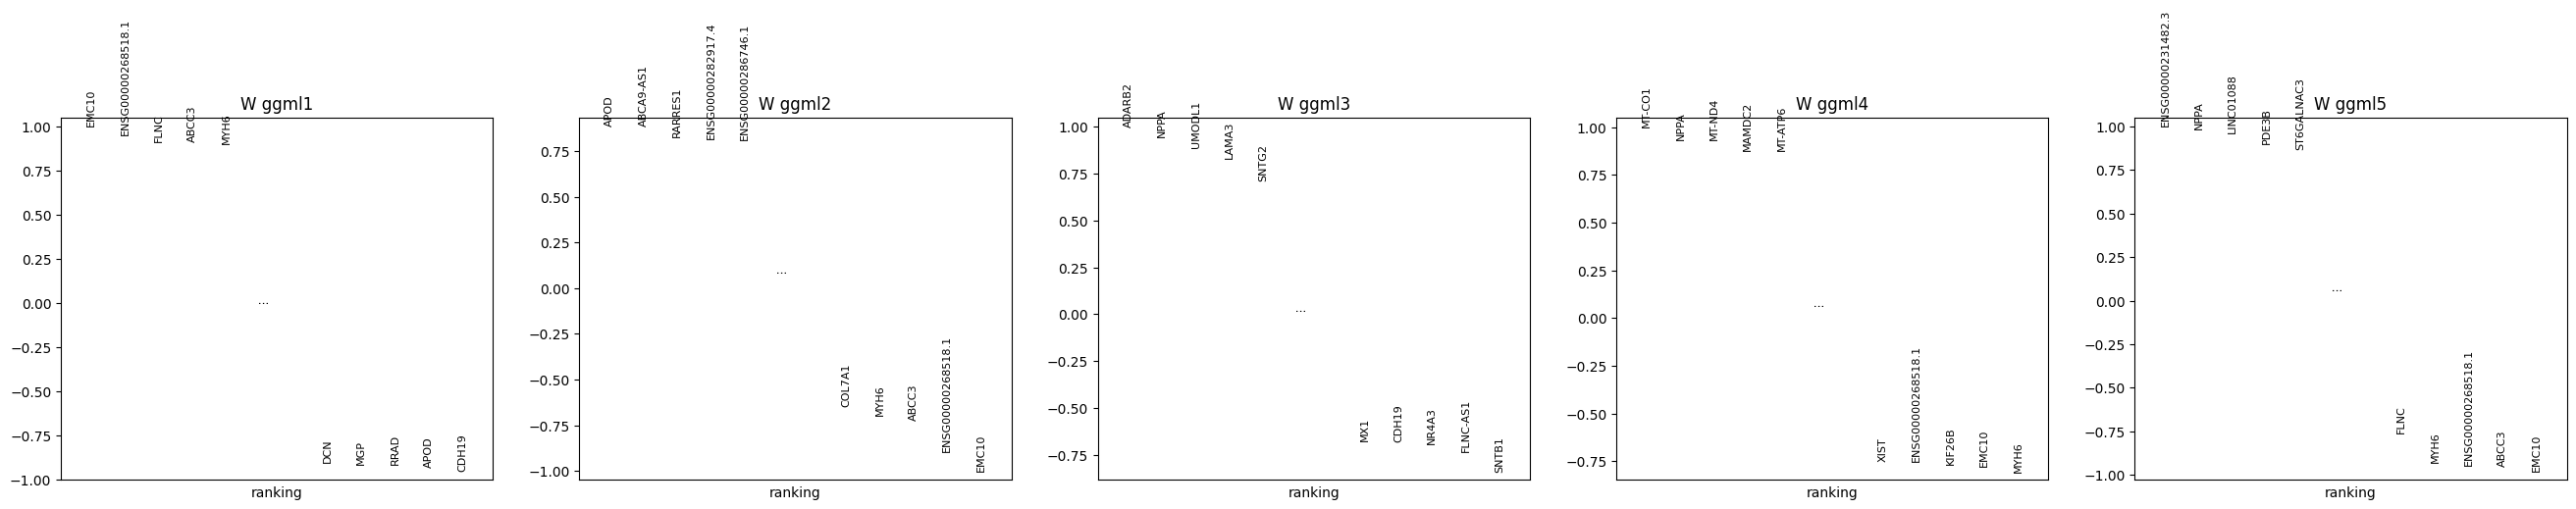

/home/kuehn/ot_metric_learning/gaussian-ground-metric-learning/code/ggml-ot_privat/ggml_ot/gene/_enrichment.py:168: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


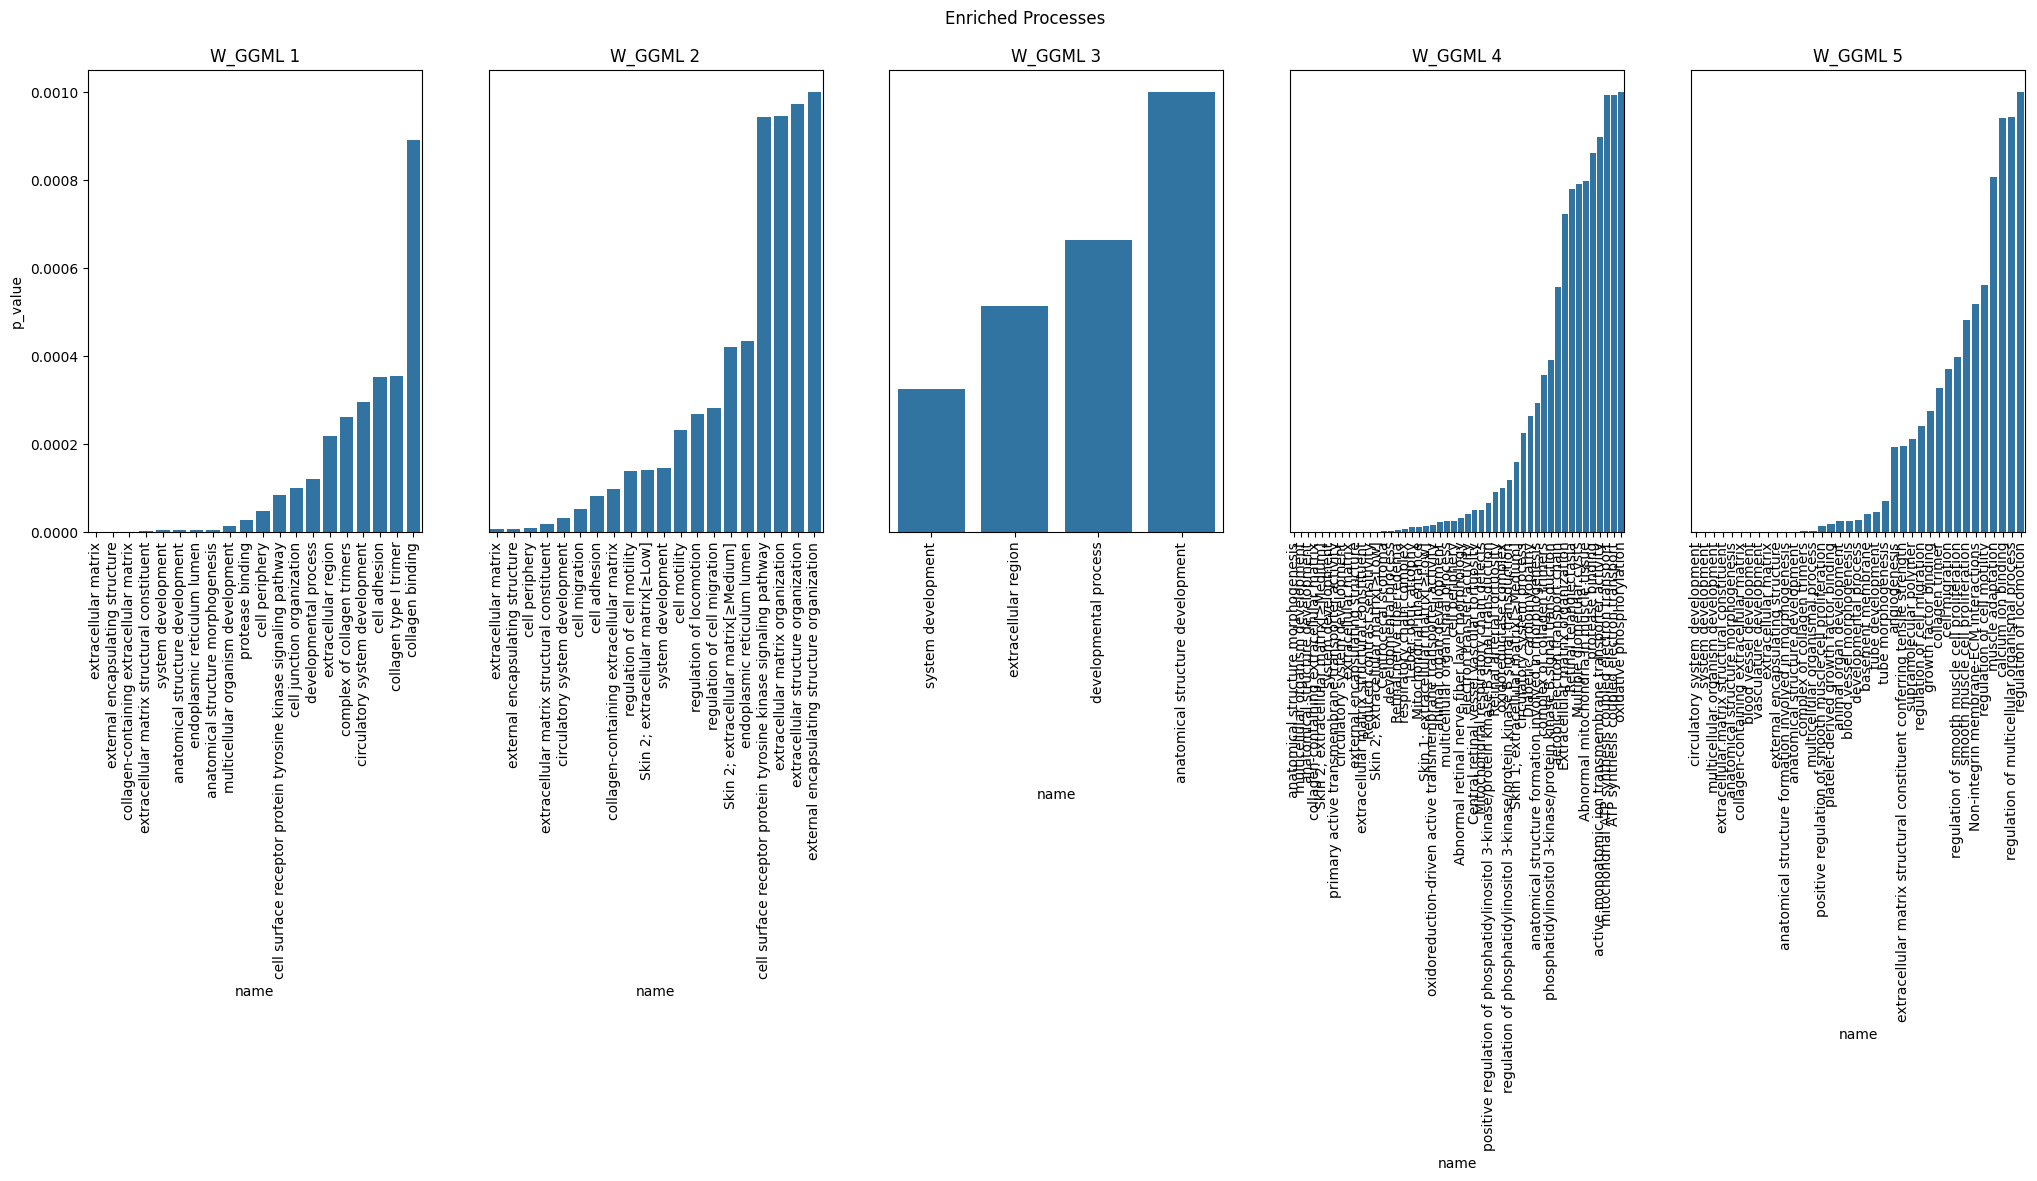

In [16]:
_ = ggml_ot.gene.ranking(adata, n_genes=10, gene_symbols="feature_name")

ggml_ot.gene.enrichment(adata, gene_symbols="feature_name", ordered=True, n_genes=100, alpha=0.001, orient="h")